In [1]:
import pandas as pd
import numpy as np
import joblib

from sklearn.model_selection import GroupShuffleSplit

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Bibliothèques importées avec succès !")

Bibliothèques importées avec succès !


In [2]:
data_training = pd.read_csv(
    "../Dataset_ProjetIA_food/data_training.csv"
)

print("Données chargées avec succès !")
print("Dimensions :", data_training.shape)

data_training.head()

Données chargées avec succès !
Dimensions : (26060, 5)


,Recipe_Name,Panier,Ingredients_Recette,Score,Texte_Complete
0,Duck and prune tagine,"4 large duck legs 400g tin chickpeas, drained ...",4 large duck legs 1 litre chicken stock 2 tbsp...,0.714286,"panier 4 large duck legs 400g tin chickpeas, d..."
1,Duck and prune tagine,1 litre chicken stock 4 tbsp ras el hanout 2 x...,4 large duck legs 1 litre chicken stock 2 tbsp...,0.285714,panier 1 litre chicken stock 4 tbsp ras el han...
2,Duck and prune tagine,"3 red onions, finely sliced 400g tin chickpeas...",4 large duck legs 1 litre chicken stock 2 tbsp...,0.428571,"panier 3 red onions, finely sliced 400g tin ch..."
3,Duck and prune tagine,2 x 400g tins chopped tomatoes 150g pitted kal...,4 large duck legs 1 litre chicken stock 2 tbsp...,0.857143,panier 2 x 400g tins chopped tomatoes 150g pit...
4,Duck and prune tagine,2 preserved lemons 2 x 400g tins chopped tomat...,4 large duck legs 1 litre chicken stock 2 tbsp...,0.500000,panier 2 preserved lemons 2 x 400g tins choppe...


In [3]:
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_index, test_index = next(
    splitter.split(
        data_training,
        data_training['Score'],
        groups=data_training['Recipe_Name']
    )
)

test_data = data_training.iloc[test_index]

y_test = test_data['Score']

print("Nombre de données de test :", len(test_data))
print("Nombre de recettes de test :",
      test_data['Recipe_Name'].nunique())

Nombre de données de test : 7820
Nombre de recettes de test : 782


In [4]:
vectorizer = joblib.load(
    "../Models/tfidf_vectorizer.pkl"
)

X_test = vectorizer.transform(
    test_data['Texte_Complete']
)

print("Vectorisation terminée !")
print("Dimensions de X_test :", X_test.shape)

Vectorisation terminée !
Dimensions de X_test : (7820, 1000)


In [5]:
trained_models = {
    "Linear Regression": joblib.load(
        "../Models/linear_regression.pkl"
    ),

    "KNN Regressor": joblib.load(
        "../Models/knn_regressor.pkl"
    ),

    "Decision Tree Regressor": joblib.load(
        "../Models/decision_tree_regressor.pkl"
    ),

    "MLP Regressor": joblib.load(
        "../Models/mlp_regressor.pkl"
    )
}

print("Les quatre modèles ont été chargés avec succès !")

Les quatre modèles ont été chargés avec succès !


In [6]:
results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    # Limiter les prédictions entre 0 et 1
    y_pred = np.clip(y_pred, 0, 1)

    mae = mean_absolute_error(y_test, y_pred)

    mse = mean_squared_error(y_test, y_pred)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })

print("Évaluation terminée !")

Évaluation terminée !


In [7]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="MAE",
    ascending=True
)

results_df

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,0.151338,0.034208,0.184954,0.166769
2,Decision Tree Regressor,0.180564,0.052110,0.228277,-0.269298
1,KNN Regressor,0.186298,0.050032,0.223679,-0.218680
3,MLP Regressor,0.202485,0.063176,0.251349,-0.538844


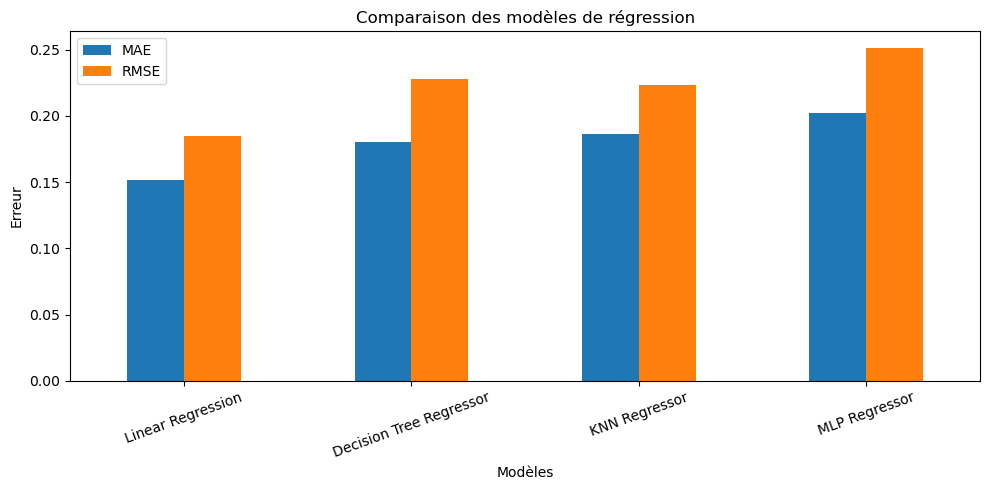

In [8]:
import matplotlib.pyplot as plt

results_df.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Comparaison des modèles de régression")
plt.ylabel("Erreur")
plt.xlabel("Modèles")
plt.xticks(rotation=20)
plt.legend()
plt.tight_layout()
plt.show()

In [9]:
best_model_name = results_df.iloc[0]["Model"]

print("Meilleur modèle :", best_model_name)

print("\nRésultats :")
print(results_df.iloc[0])

Meilleur modèle : Linear Regression

Résultats :
Model    Linear Regression
MAE               0.151338
MSE               0.034208
RMSE              0.184954
R2                0.166769
Name: 0, dtype: object
